In [ ]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV, StratifiedKFold

from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from xgboost import XGBClassifier

# Загрузка файлов

In [ ]:
!pip install -q -quiet kaggle


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: -u


In [ ]:
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"danilakopitayko","key":"aeed7b69194bfed4a166373ef00134a6"}'}

In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle
!chmod 600 ~/.kaggle/kaggle.json
! kaggle datasets list

ref                                                            title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
wardabilal/spotify-global-music-dataset-20092025               Spotify Global Music Dataset (2009–2025)               1289021  2025-11-11 09:43:05.933000           6657        147  1.0              
sadiajavedd/students-academic-performance-dataset              Students_Academic_Performance_Dataset                     8907  2025-10-23 04:16:35.563000          12082        299  1.0              
ahmadrazakashif/global-football-goalscorers-dataset            Global Football Goalscorers Dataset                    1213044  2025-11-14 18:25:57.453000            913         23  1.0              
kunda

In [ ]:
!kaggle competitions download -c bank-churn-competition-by-msu-x-mts-base-ml-course

  0% 0.00/637k [00:00<?, ?B/s]
100% 637k/637k [00:00<00:00, 826MB/s]


In [ ]:
!mkdir train
!unzip /content/bank-churn-competition-by-msu-x-mts-base-ml-course.zip -d train

Archive:  /content/bank-churn-competition-by-msu-x-mts-base-ml-course.zip
  inflating: train/sample_submission.csv  
  inflating: train/test.csv          
  inflating: train/train.csv         


# Первичный анализ

In [ ]:
test = pd.read_csv('/content/train/test.csv')
train = pd.read_csv('/content/train/train.csv')
sample_submission = pd.read_csv('/content/train/sample_submission.csv')

In [ ]:
train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15653521.0,Nkemakonam,667.0,Germany,Male,33.0,3.0,131769.04,1.0,1.0,1.0,162719.69,0.0
1,1,15699005.0,Chiekwugo,614.0,France,Female,31.0,2.0,110615.47,1.0,1.0,1.0,181879.56,0.0
2,2,15656912.0,Chiang,683.0,Germany,Female,24.0,6.0,115074.02,2.0,1.0,0.0,109688.82,0.0
3,3,15700772.0,Ch'ang,678.0,France,Female,38.0,9.0,0.00,1.0,1.0,0.0,122823.84,1.0
4,4,15583850.0,Chiang,588.0,Spain,Female,39.0,3.0,0.00,2.0,1.0,1.0,136910.18,0.0


In [ ]:
test.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,15000,15646539.0,Onyemauchechukwu,821.0,Spain,Male,32.0,3.0,0.00,1.0,1.0,1.0,120893.85
1,15001,15628144.0,Chikwado,634.0,France,Male,28.0,1.0,129299.28,1.0,1.0,0.0,179655.85
2,15002,15687953.0,Ting,713.0,France,Male,42.0,1.0,0.00,2.0,1.0,1.0,80552.12
3,15003,15585067.0,Achebe,611.0,France,Female,38.0,3.0,0.00,1.0,0.0,1.0,151335.24
4,15004,15746190.0,Chiazagomekpere,724.0,France,Male,29.0,9.0,0.00,1.0,1.0,1.0,88724.49


In [ ]:
sample_submission.head()

,id,Exited
0,15000,0.5
1,15001,0.5
2,15002,0.5
3,15003,0.5
4,15004,0.5


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  object 
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  object 
 5   Gender           15000 non-null  object 
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), object(3)
memory usage: 1.6+ MB


Для обучения модели для предсказания, уйдет ли клиент, используется таблица из 15000 строк с 12 признаками.

•   Customer ID: Уникальный идентификатор каждого клиента.

•   Surname: Фамилия клиента.

•   Credit Score: Числовое значение, представляющее кредитный рейтинг клиента.

•   Geography: Страна проживания клиента (Франция, Испания или Германия).

•   Gender: Пол клиента (Мужской или Женский).

•   Age: Возраст клиента.

•   Tenure: Количество лет, которое клиент обслуживается в банке.

•   Balance: Баланс на счёте клиента.

•   NumOfProducts: Количество банковских продуктов, которыми пользуется клиент
(например, сберегательный счёт, кредитная карта).

•   HasCrCard: Наличие кредитной карты у клиента (1 = да, 0 = нет).

•   IsActiveMember: Является ли клиент активным членом банка (1 = да, 0 = нет).

•   EstimatedSalary: Предполагаемая заработная плата клиента.

•   Exited: Ушёл ли клиент (1 = да, 0 = нет).

In [ ]:
train.Exited.sum()

np.float64(3118.0)

In [ ]:
train.CustomerId.nunique()

6359

Видно, что уникальных идентификаторов клиентов сильно меньше, чем строк в таблице, то есть, нескольким клиентам соответствует один и тот же id.

Ниже - пример ID, для которого несколько записей в таблице.

In [ ]:
train[train['CustomerId']==train.CustomerId.unique()[400]]

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
419,419,15741417.0,Pinto,679.0,France,Male,31.0,4.0,0.00,2.0,1.0,0.0,165576.55,0.0
2538,2538,15741417.0,Lombardi,559.0,France,Male,40.0,5.0,0.00,1.0,1.0,0.0,184842.21,1.0
5475,5475,15741417.0,Nwankwo,705.0,Spain,Male,50.0,8.0,0.00,1.0,1.0,0.0,123876.87,1.0
5657,5657,15741417.0,Hsiung,605.0,France,Male,32.0,2.0,101465.31,2.0,1.0,1.0,60906.12,0.0
8655,8655,15741417.0,Onuchukwu,580.0,France,Male,29.0,9.0,0.00,2.0,1.0,1.0,178028.96,0.0


Будем считать, что CustomerId в паре с Surname составляет уникальный ключ. Не все строки удовлетворяют этому критерию, но их немного - 116, поэтому их можно удалить.

In [ ]:
#train = train.drop_duplicates(subset = ['CustomerId','Surname'])

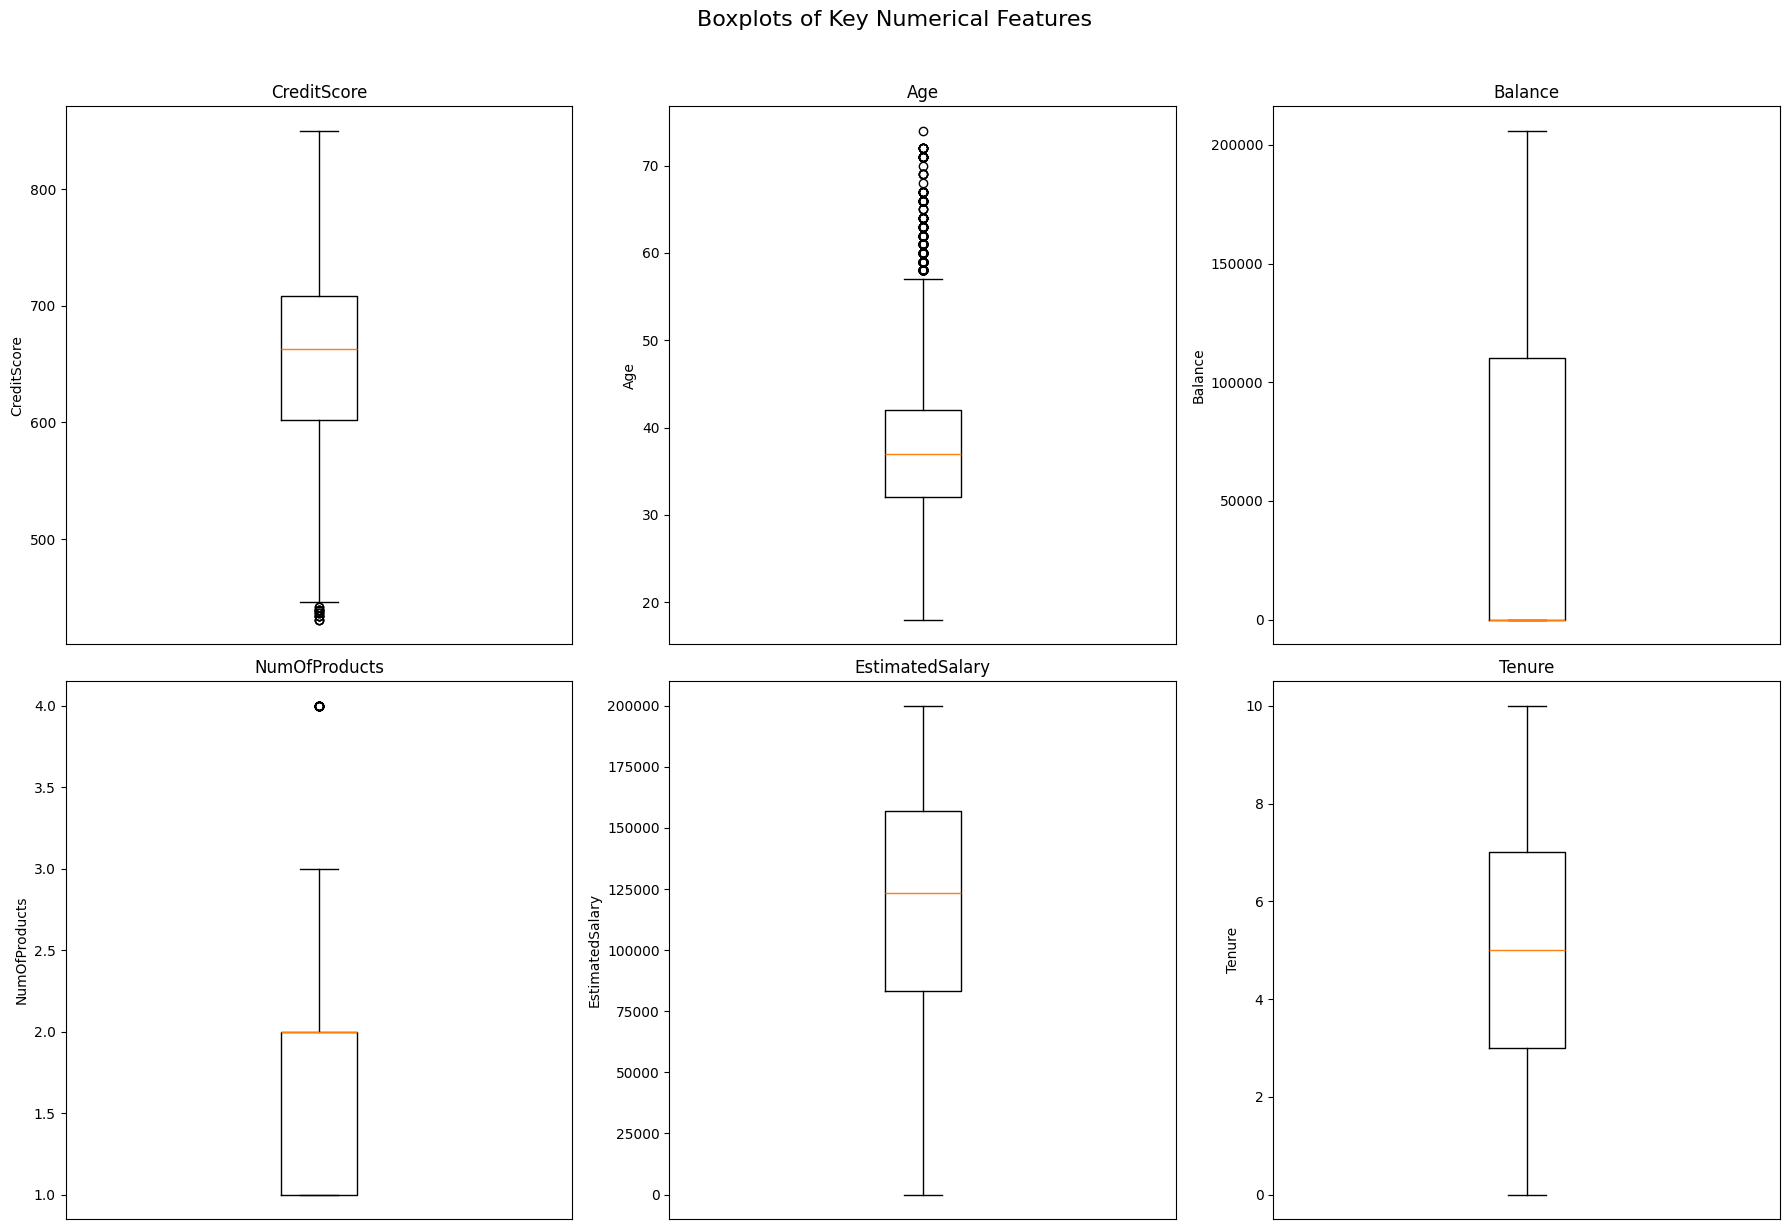

In [ ]:
cols = ['CreditScore', 'Age', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Tenure']


fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, column in enumerate(cols):
    axes[i].boxplot(train[column])
    axes[i].set_title(f'{column}')
    axes[i].set_xticks([])
    axes[i].set_ylabel(column)


if len(cols) < len(axes):
    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

fig.suptitle('Boxplots of Key Numerical Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
def calculate_boundaries(feature):
  upper = train[feature].quantile(0.75)
  lower = train[feature].quantile(0.25)
  IQR = upper - lower
  return lower - 1.5*IQR, upper + 1.5*IQR

print(f'Age outliers : {train[train['Age'] > calculate_boundaries('Age')[1]]['id'].count()}')

print(f'CreditScore outliers : {train[train['CreditScore'] < calculate_boundaries('CreditScore')[0]]['id'].count()}')

print(f'Num of products outliers : {train[train['NumOfProducts'] > calculate_boundaries('NumOfProducts')[1]]['id'].count()}')


print('Proportion of total outlier to total dataframe',(train[train['NumOfProducts'] > calculate_boundaries('NumOfProducts')[1]]['id'].count() + \
      train[train['Age'] > calculate_boundaries('Age')[1]]['id'].count() + \
      train[train['CreditScore'] < calculate_boundaries('CreditScore')[0]]['id'].count()) / len(train))

Age outliers : 384
CreditScore outliers : 17
Num of products outliers : 20
Proportion of total outlier to total dataframe 0.028066666666666667


Выбросов в общей сумме чуть меньше 3%, их можно выбросить.

In [ ]:
'''
age_lower, age_upper = calculate_boundaries('Age')
credit_score_lower, credit_score_upper = calculate_boundaries('CreditScore')
num_products_lower, num_products_upper = calculate_boundaries('NumOfProducts')

train = train[
    (train['Age'] < age_upper) &
    (train['CreditScore'] > credit_score_lower) &
    (train['NumOfProducts'] < num_products_upper)
]
'''

"\nage_lower, age_upper = calculate_boundaries('Age')\ncredit_score_lower, credit_score_upper = calculate_boundaries('CreditScore')\nnum_products_lower, num_products_upper = calculate_boundaries('NumOfProducts')\n\ntrain = train[\n    (train['Age'] < age_upper) &\n    (train['CreditScore'] > credit_score_lower) &\n    (train['NumOfProducts'] < num_products_upper)\n]\n"

In [ ]:
clients = ("Exited", "Didn't exit")
gender = {
    'Male': (train[(train['Exited']==1) & (train['Gender']=='Male')]['id'].count()/train[(train['Exited']==1)]['id'].count(), train[(train['Exited']==0) & (train['Gender']=='Male')]['id'].count()/train[(train['Exited']==0)]['id'].count()),
    'Female': (train[(train['Exited']==1) & (train['Gender']=='Female')]['id'].count()/train[(train['Exited']==1)]['id'].count(), train[(train['Exited']==0) & (train['Gender']=='Female')]['id'].count()/train[(train['Exited']==0)]['id'].count()),
}

country = {
    'France': (train[(train['Exited']==1) & (train['Geography']=='France')]['id'].count()/train[(train['Geography']=='France')]['id'].count(), train[(train['Exited']==0) & (train['Geography']=='France')]['id']\
               .count()/train[(train['Geography']=='France')]['id'].count()),
    'Germany': (train[(train['Exited']==1) & (train['Geography']=='Germany')]['id'].count()/train[(train['Geography']=='Germany')]['id'].count(), train[(train['Exited']==0) & (train['Geography']=='Germany')]\
     ['id'].count()/train[(train['Geography']=='Germany')]['id'].count()),
    'Spain': (train[(train['Exited']==1) & (train['Geography']=='Spain')]['id'].count()/train[(train['Geography']=='Spain')]['id'].count(), train[(train['Exited']==0) & (train['Geography']=='Spain')]\
     ['id'].count()/train[(train['Geography']=='Spain')]['id'].count()),
}

<BarContainer object of 3 artists>

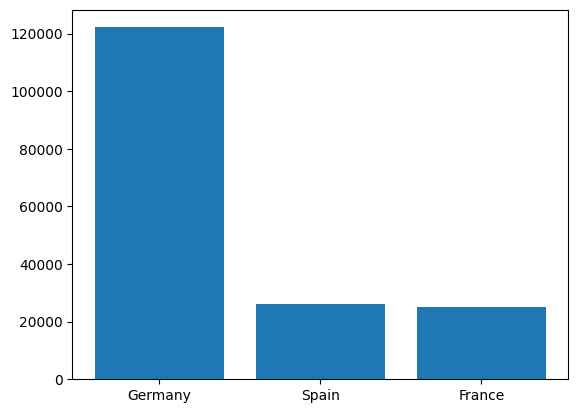

In [ ]:
balance_germany = train[train['Geography']=='Germany']['Balance'].mean()
balance_spain = train[train['Geography']=='Spain']['Balance'].mean()
balance_france = train[train['Geography']=='France']['Balance'].mean()

plt.bar(['Germany','Spain','France'],[balance_germany,balance_spain,balance_france])

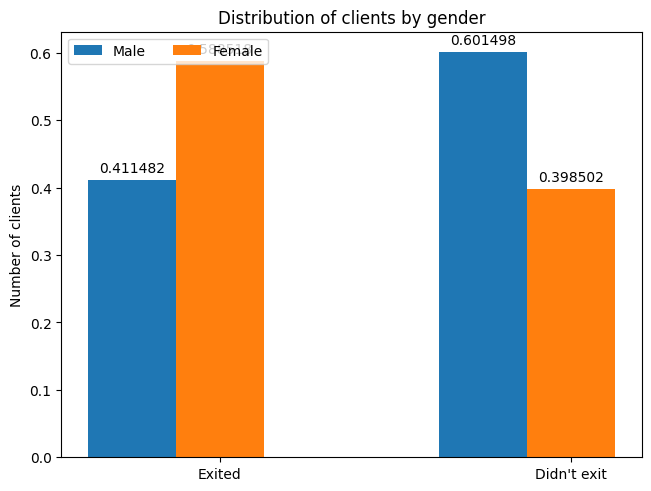

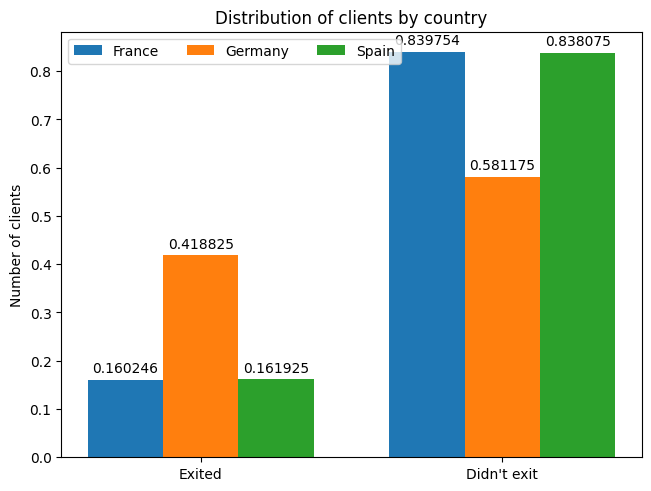

In [ ]:
x = np.arange(len(clients))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in gender.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Number of clients')
ax.set_title('Distribution of clients by gender')
ax.set_xticks(x + width, clients)
ax.legend(loc='upper left', ncols=3)
#ax.set_ylim(0, 250)

plt.show()
'''========================================================================='''
#x = np.arange(len(clients))  # the label locations
#width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in country.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Number of clients')
ax.set_title('Distribution of clients by country')
ax.set_xticks(x + width, clients)
ax.legend(loc='upper left', ncols=3)
#ax.set_ylim(0, 250)

plt.show()

Среди ушедших больше женщин, среди тех, кто остался больше мужчин, почти в два раза. Также ушедших больше всего французов, и оставшихся тоже больше французов с большим отрывом. Среди ушедших меньше всего испанцев и среди оставшихся меньше всего немцев.

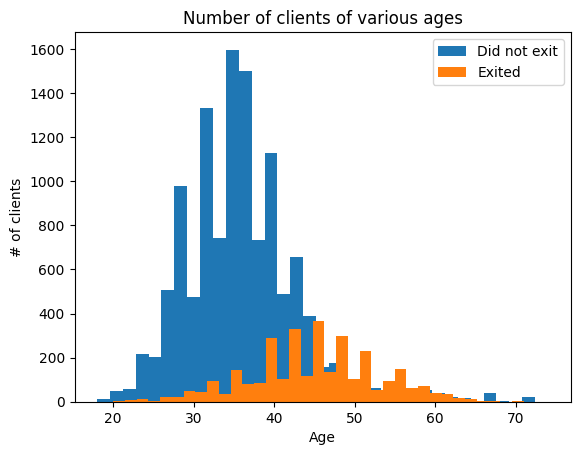

In [ ]:
train[train['Exited']==0]['Age'].plot.hist(bins=35,xlabel='Age',ylabel='# of clients',title='Number of clients of various ages',label='Did not exit')
train[train['Exited']==1]['Age'].plot.hist(bins=35,xlabel='Age',ylabel='# of clients',title='Number of clients of various ages',label='Exited')
plt.legend()
plt.show()



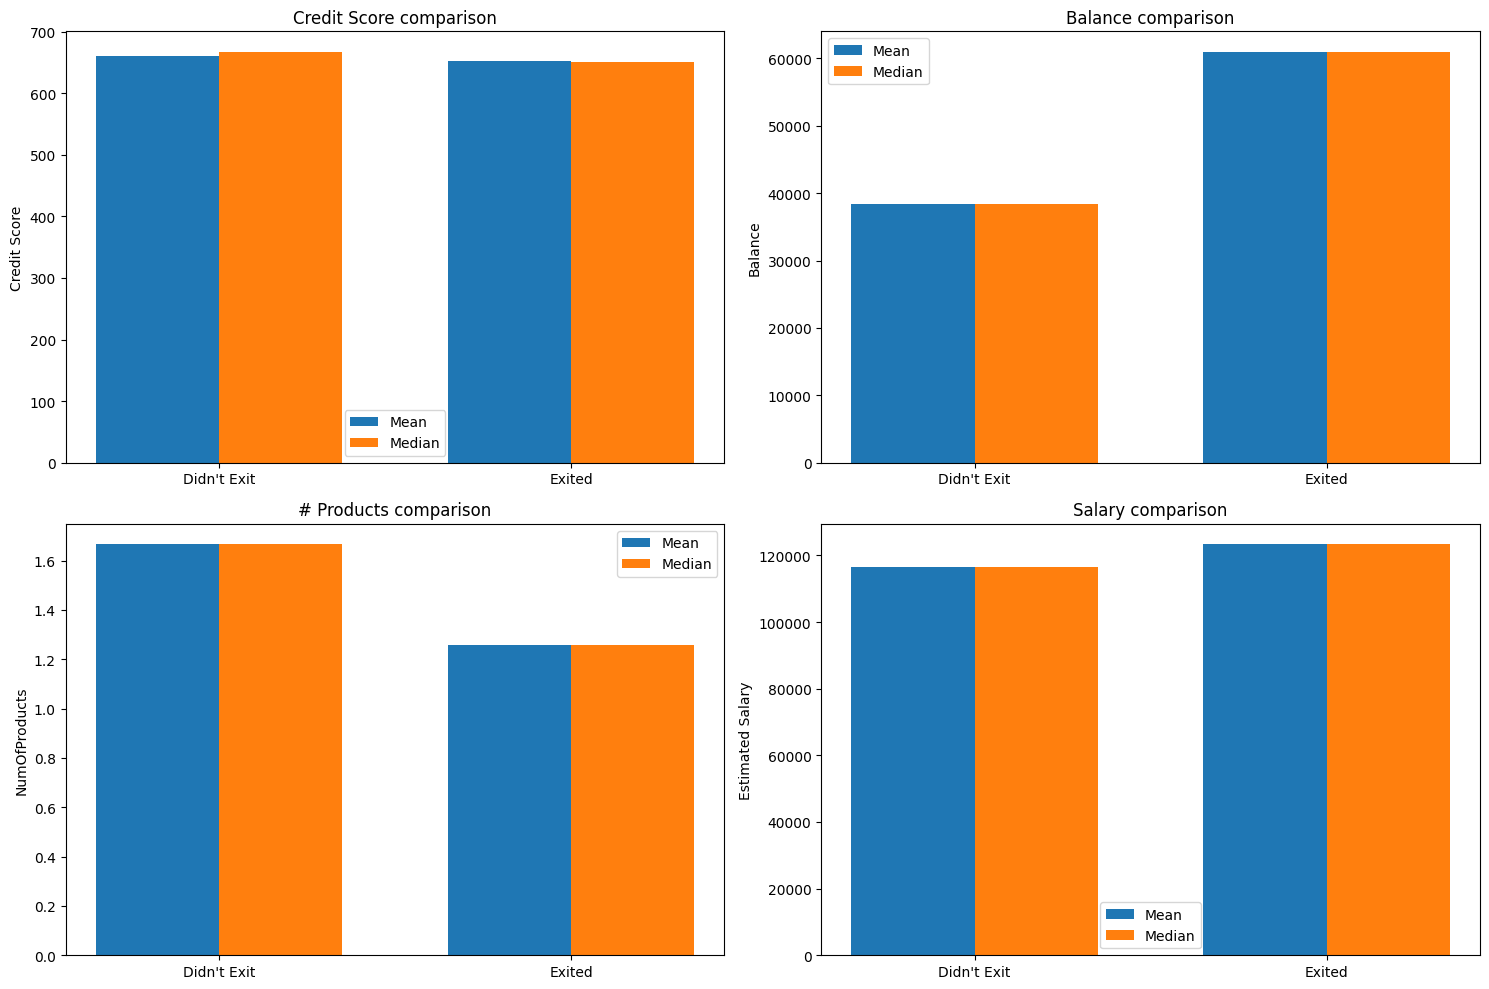

In [ ]:
labels = ["Didn't Exit", "Exited"]

mean_scores = [train[train['Exited']==0]['CreditScore'].mean(), train[train['Exited']==1]['CreditScore'].mean()]
median_scores = [train[train['Exited']==0]['CreditScore'].median(), train[train['Exited']==1]['CreditScore'].median()]

balance_mean = [train[train['Exited']==0]['Balance'].mean(), train[train['Exited']==1]['Balance'].mean()]
balance_median = [train[train['Exited']==0]['Balance'].mean(), train[train['Exited']==1]['Balance'].mean()]

prod_mean = [train[train['Exited']==0]['NumOfProducts'].mean(), train[train['Exited']==1]['NumOfProducts'].mean()]
prod_median = [train[train['Exited']==0]['NumOfProducts'].mean(), train[train['Exited']==1]['NumOfProducts'].mean()]

salary_mean = [train[train['Exited']==0]['EstimatedSalary'].mean(), train[train['Exited']==1]['EstimatedSalary'].mean()]
salary_median = [train[train['Exited']==0]['EstimatedSalary'].mean(), train[train['Exited']==1]['EstimatedSalary'].mean()]

x = np.arange(len(labels))
width = 0.35

fig, axs = plt.subplots(2,2, figsize=(15,10))
rects1 = axs[0][0].bar(x - width/2, mean_scores, width, label='Mean')
rects2 = axs[0][0].bar(x + width/2, median_scores, width, label='Median')

rects3 = axs[0][1].bar(x - width/2, balance_mean, width, label='Mean')
rects4 = axs[0][1].bar(x + width/2, balance_median, width, label='Median')

rects5 = axs[1][0].bar(x - width/2, prod_mean, width, label='Mean')
rects6 = axs[1][0].bar(x + width/2, prod_median, width, label='Median')

rects7 = axs[1][1].bar(x - width/2, salary_mean, width, label='Mean')
rects8 = axs[1][1].bar(x + width/2, salary_median, width, label='Median')

axs[0][0].set_ylabel('Credit Score')
axs[0][0].set_title('Credit Score comparison')
axs[0][0].set_xticks(x, labels)
axs[0][0].legend()

axs[0][1].set_ylabel('Balance')
axs[0][1].set_title('Balance comparison')
axs[0][1].set_xticks(x, labels)
axs[0][1].legend()

axs[1][0].set_ylabel('NumOfProducts')
axs[1][0].set_title('# Products comparison')
axs[1][0].set_xticks(x, labels)
axs[1][0].legend()

axs[1][1].set_ylabel('Estimated Salary')
axs[1][1].set_title('Salary comparison')
axs[1][1].set_xticks(x, labels)
axs[1][1].legend()




fig.tight_layout()
plt.show()

In [ ]:
#train.drop(columns={'CreditScore'},inplace=True)

Соотношение средних и медианных кредитных рейтингов примерно одинаково для тех, кто ушел и кто остался.


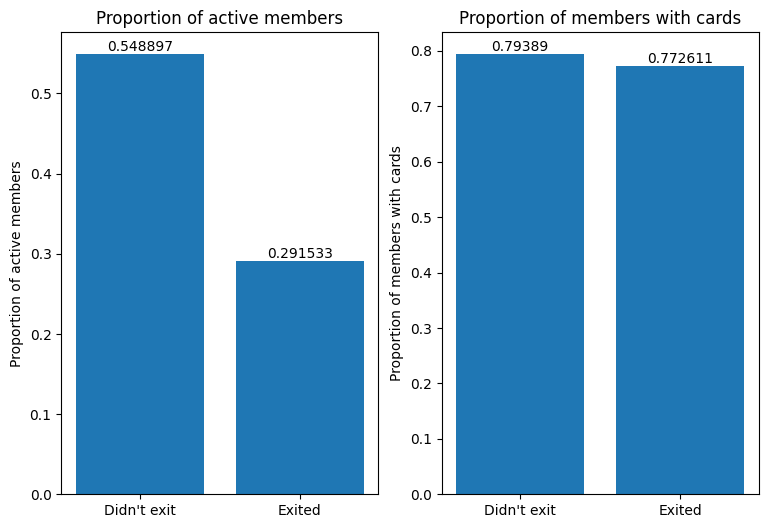

In [ ]:
active_members  = [train[train['Exited']==0]['IsActiveMember'].sum() / len(train[train['Exited']==0]),\
                   train[train['Exited']==1]['IsActiveMember'].sum() / len(train[train['Exited']==1])]

has_card  = [train[train['Exited']==0]['HasCrCard'].sum() / len(train[train['Exited']==0]),\
                   train[train['Exited']==1]['HasCrCard'].sum() / len(train[train['Exited']==1])]




fig, ax = plt.subplots(1,2,figsize=(9, 6))

bars = ax[0].bar(["Didn't exit","Exited"], active_members)
ax[0].set_ylabel('Proportion of active members')
ax[0].bar_label(bars)
ax[0].set_title("Proportion of active members")



bars = ax[1].bar(["Didn't exit","Exited"], has_card)
ax[1].set_ylabel('Proportion of members with cards')
ax[1].bar_label(bars)
ax[1].set_title("Proportion of members with cards")


plt.show()

In [ ]:
#Удалим столбец HasCrCard, потому что он почти одинаковое относительное количество пользователей с картой и без остались
train.drop(columns={'HasCrCard'},inplace=True)

In [ ]:
#train.reset_index(drop=True,inplace=True)

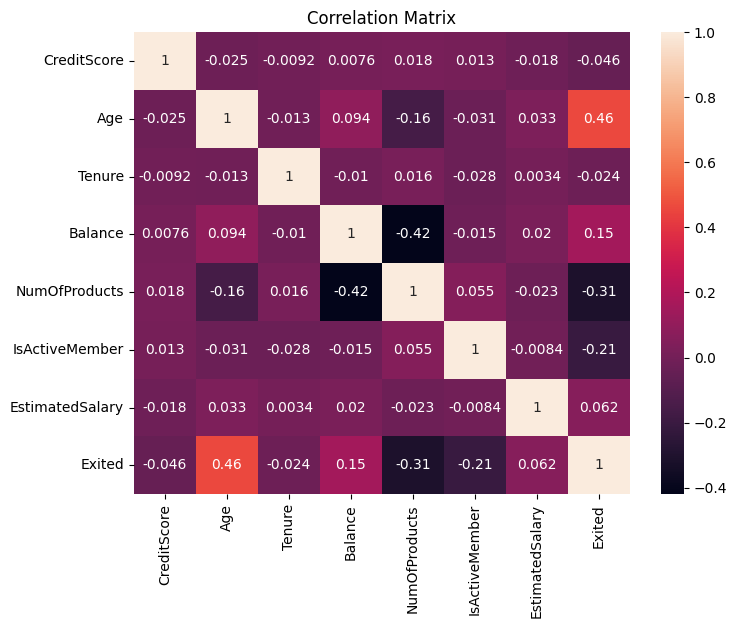

In [ ]:
import seaborn as sns

corr_matrix = train[['CreditScore','Age','Tenure','Balance','NumOfProducts','IsActiveMember','EstimatedSalary','Exited']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True)
plt.title('Correlation Matrix')
plt.show()

# Создание модели

In [ ]:
X = train.drop(columns=['Exited','id','CustomerId','Surname'])
Y = train['Exited']

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size = 0.3, random_state = 42)

X_train.reset_index(drop=True,inplace=True)
X_test.reset_index(drop=True,inplace=True)
Y_train.reset_index(drop=True, inplace=True)
Y_test.reset_index(drop=True, inplace=True)

In [ ]:
#
# ПОПРОБОВАТЬ ДОБАВИТЬ TENURE, NUMOFPRODUCTS В КАТЕГОРИАЛЬНЫЕ ПЕРЕМЕННЫЕ
#

numerical = ['CreditScore', 'Age','Tenure', 'Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary']

categorical = ['Geography','Gender']

## OneHotEncoder

In [ ]:
encoder = OneHotEncoder(sparse_output = False)
categorical_ = encoder.fit_transform(X_train[categorical])
categorical_test = encoder.transform(X_test[categorical])

In [ ]:
categorical_df = pd.DataFrame(categorical_,columns=encoder.get_feature_names_out(categorical))
categorical_test_df = pd.DataFrame(categorical_test,columns=encoder.get_feature_names_out(categorical))
categorical_test_df

,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,1.0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,1.0,0.0
2,0.0,0.0,1.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...
4495,1.0,0.0,0.0,0.0,1.0
4496,1.0,0.0,0.0,1.0,0.0
4497,0.0,1.0,0.0,1.0,0.0
4498,1.0,0.0,0.0,0.0,1.0


In [ ]:
X_train = pd.concat([X_train[numerical],categorical_df],axis=1)
X_test = pd.concat([X_test[numerical],categorical_test_df],axis=1)

## StandardScaler

In [ ]:
scaler = StandardScaler()

scaled = scaler.fit_transform(X_train[['CreditScore', 'Age','Tenure', 'Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary']])


scaled_test = scaler.transform(X_test[['CreditScore', 'Age','Tenure','Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary']])

In [ ]:
scaled = pd.DataFrame(scaled,columns = ['CreditScore', 'Age','Tenure', 'Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary'])
scaled_test = pd.DataFrame(scaled_test,columns = ['CreditScore', 'Age','Tenure','Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary'])

X_train.drop(columns = ['CreditScore', 'Age','Tenure','Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary'],inplace=True)
X_test.drop(columns = ['CreditScore', 'Age','Tenure','Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary'],inplace=True)


In [ ]:
X_train.head()

,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,1.0,0.0
4,1.0,0.0,0.0,1.0,0.0


In [ ]:
X_train = pd.concat((scaled,X_train),axis=1)
X_test = pd.concat((scaled_test,X_test),axis=1)

X_test.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,0.004506,0.274720,-0.014633,1.624082,-1.092697,1.014003,0.291539,1.0,0.0,0.0,0.0,1.0
1,-0.655442,-0.092241,1.057314,-0.725554,0.792502,1.014003,-2.018829,0.0,0.0,1.0,1.0,0.0
2,-0.325468,0.397040,0.699998,-0.725554,0.792502,1.014003,1.359371,0.0,0.0,1.0,0.0,1.0
3,0.760696,-0.581523,0.699998,-0.725554,0.792502,1.014003,-0.814813,1.0,0.0,0.0,0.0,1.0
4,0.760696,0.397040,-1.086580,-0.725554,0.792502,1.014003,1.499642,1.0,0.0,0.0,1.0,0.0


# XGBoost

In [ ]:
best_boost_params = {'colsample_bylevel': 1.0,
                      'colsample_bynode': 1.0,
                      'colsample_bytree': 1.0,
                      'gamma': np.float64(3.0705345194334823),
                      'learning_rate': np.float64(0.16752548479068588),
                      'max_delta_step': 6,
                      'max_depth': 4,
                      'min_child_weight': 9,
                      'n_estimators': 211,
                      'reg_alpha': np.float64(7.837917844853973),
                      'reg_lambda': np.float64(5.542265141320167),
                      'scale_pos_weight': 2,
                      'subsample': 1.0
                     }

best_boost = XGBClassifier(
    objective='binary:logistic',
    verbosity=0,
    n_jobs=-1,  # Используем все ядра
    random_state=42,
    eval_metric='logloss',
    **best_boost_params
)

# Convert AgeGroup to integer type if it's categorical
if 'AgeGroup' in X_train.columns and pd.api.types.is_categorical_dtype(X_train['AgeGroup']):
    X_train['AgeGroup'] = X_train['AgeGroup'].astype(int)
    X_test['AgeGroup'] = X_test['AgeGroup'].astype(int)

best_boost.fit(X_train,Y_train)

y_pred = best_boost.predict_proba(X_test)[:,1]

roc_auc_score(Y_test, y_pred)

np.float64(0.9300700929173612)